# 📗 Notebook 9 — Case Study 3.2: Styrene / MMA Free-Radical Copolymerization
| | |
|---|---|
| ⏱ Time | ~40 min (simulations ≈ 20 s) |
| 🧭 Type | **steady state Monte Carlo**: Terminal model |
| 🎯 Goal | reproduce **Figures 3.9, 3.10, 3.14 and 3.16** with the book's parameters |
| 📖 Book | Sec. 3.2 · Tables 3.4–3.5 · Algorithm 3.3 · Stockmayer distribution (Eqs. 3.58–3.65) |

M1 = styrene, M2 = methyl methacrylate (MMA). Polymer radicals ending in M1 are **P**, those ending in M2 are **Q**. This notebook focuses on the code; the theory is in *Monte Carlo Methods in Polymer Reaction Engineering: From Mechanisms to Molecular Architecture*. As in Notebook 8, we use **Numba** (`@njit`) for speed.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm
from numba import njit

if not hasattr(np, "trapezoid"):
    np.trapezoid = np.trapz

## 1 · Kinetic parameters (Table 3.5)
Same Arrhenius form as Case Study 3.1 (cal/mol, min⁻¹, L/(mol·min)).

In [2]:
R_gas, T = 1.987, 90 + 273.15

def arrhenius(A, E):
    return A * np.exp(-E / (R_gas * T))

In [3]:
M_tot, I, f = 8.0, 0.016, 0.7                 # mol/L, mol/L, –
kd  = arrhenius(3.389e15, 31500)
ki1 = arrhenius(1e9, 7000)
ki2 = arrhenius(3e9, 7000)

Styrene (1) and MMA (2) homo-constants, and the reactivity ratios:

In [4]:
kp11, ktM11, ktc11 = arrhenius(1.302e9, 7759), arrhenius(5.14e9, 15230), arrhenius(4.92e11, 3470)
kp22, ktM22, ktc22 = arrhenius(2.95e7, 4353), arrhenius(2.41e9, 15541), arrhenius(5.88e9, 701)
r1, r2 = 0.5224, 0.4839

Cross constants, built from the homo-constants exactly as in Table 3.5:

In [5]:
kp12 = kp11 / r1
kp21 = kp22 / r2
ktc12 = ktc21 = np.sqrt(2 * ktc11 * ktc22) * 25      # φ = 25
ktM12 = ktM21 = np.sqrt(ktM11 * ktM22)

## 2 · The probabilities, step by step (Sec. 3.2.1–3.2.4)
### Step 1 · Radical concentrations: QSSA + LCA-II
Eqs. 3.53–3.57: `[Q] = ϕ[P]` and `[P] = √(f·k_d·[I] / k̂_tc)`.

In [6]:
def radical_concentrations(f1):
    M1, M2 = f1 * M_tot, (1 - f1) * M_tot
    phi = kp12 * M2 / (kp21 * M1)                        # Eq. 3.54
    khat = ktc11 + 2 * ktc12 * phi + ktc22 * phi**2      # Eq. 3.56
    P = np.sqrt(f * kd * I / khat)                       # Eq. 3.57
    return M1, M2, P, phi * P

### Step 2 · Propagation
Probability that P or Q propagates (Eqs. 3.34, 3.36), and that the added unit is M1 (Eqs. 3.37, 3.40):

In [7]:
def propagation_probabilities(M1, M2, P, Q):
    grow1 = kp11 * M1 + kp12 * M2
    grow2 = kp21 * M1 + kp22 * M2
    Pp1 = grow1 / (grow1 + ktM11*M1 + ktM12*M2 + ktc11*P + ktc12*Q)
    Pp2 = grow2 / (grow2 + ktM21*M1 + ktM22*M2 + ktc21*P + ktc22*Q)
    Pp11 = r1 * M1 / (r1 * M1 + M2)
    Pp21 = M1 / (M1 + r2 * M2)
    return Pp1, Pp2, Pp11, Pp21

### Step 3 · Combination or transfer, and which monomer receives the transfer
Eqs. 3.43, 3.45, 3.47, 3.49:

In [8]:
def termination_probabilities(M1, M2, P, Q):
    comb1 = ktc11 * P + ktc12 * Q
    comb2 = ktc21 * P + ktc22 * Q
    Ptc1 = comb1 / (comb1 + ktM11 * M1 + ktM12 * M2)
    Ptc2 = comb2 / (comb2 + ktM21 * M1 + ktM22 * M2)
    PtM11 = ktM11 * M1 / (ktM11 * M1 + ktM12 * M2)
    PtM21 = ktM21 * M1 / (ktM21 * M1 + ktM22 * M2)
    return Ptc1, Ptc2, PtM11, PtM21

### Step 4 · Initiation with M1 (Eq. 3.31), and all together

In [9]:
def all_probabilities(f1):
    M1, M2, P, Q = radical_concentrations(f1)
    Pp1, Pp2, Pp11, Pp21 = propagation_probabilities(M1, M2, P, Q)
    Ptc1, Ptc2, PtM11, PtM21 = termination_probabilities(M1, M2, P, Q)
    Pi1 = ki1 * M1 / (ki1 * M1 + ki2 * M2)
    return {"Pi1": Pi1, "Pp1": Pp1, "Pp2": Pp2, "Pp11": Pp11, "Pp21": Pp21,
            "Ptc1": Ptc1, "Ptc2": Ptc2, "PtM11": PtM11, "PtM21": PtM21}

In [10]:
feeds = [0.1, 0.5, 0.9]
table = pd.DataFrame()
for f1 in feeds:
    table[f"f1 = {f1}"] = pd.Series(all_probabilities(f1))
table.round(6)

,f1 = 0.1,f1 = 0.5,f1 = 0.9
Pi1,0.035714,0.250000,0.750000
Pp1,0.997886,0.998996,0.999269
Pp2,0.999552,0.999108,0.998254
Pp11,0.054860,0.343142,0.824611
Pp21,0.186738,0.673900,0.948977
Ptc1,0.980551,0.933349,0.849443
Ptc2,0.967140,0.984503,0.992388
PtM11,0.167561,0.644331,0.942211
PtM21,0.167561,0.644331,0.942211


### The overall rates, for Figure 3.10 and for the Stockmayer solution
`R_p`, `R_tM`, `R_tc` (Eqs. 3.24, 3.27, 3.30), and `β = R_tc/R_p`, `τ = R_tM/R_p` (Eqs. 3.62–3.63):

In [11]:
def overall_rates(f1):
    M1, M2, P, Q = radical_concentrations(f1)
    Rp  = (kp11*M1 + kp12*M2) * P + (kp21*M1 + kp22*M2) * Q
    RtM = (ktM11*M1 + ktM12*M2) * P + (ktM21*M1 + ktM22*M2) * Q
    Rtc = (ktc11*P + ktc12*Q) * P + (ktc21*P + ktc22*Q) * Q
    return P, Q, Rp, RtM, Rtc

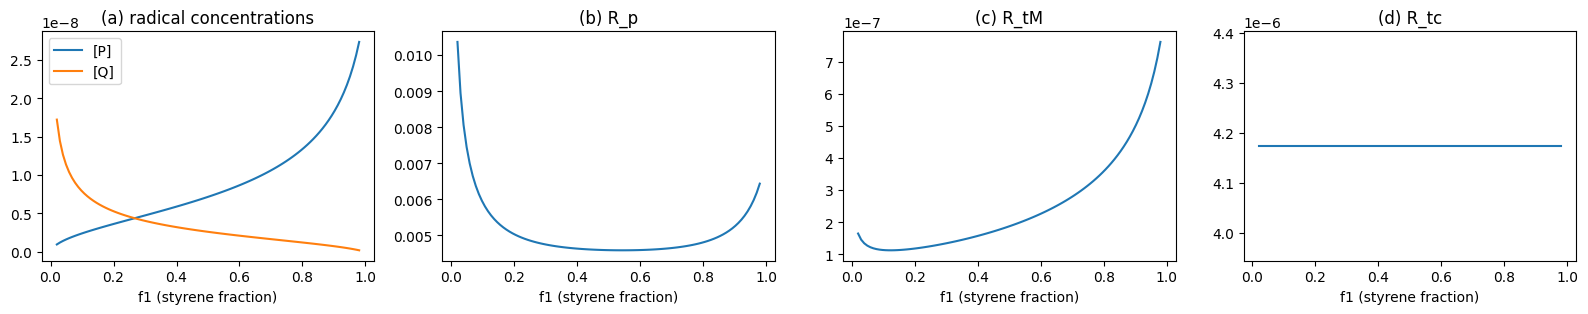

In [12]:
#@title Plot Figure 3.10
f_grid = np.linspace(0.02, 0.98, 100); vals = np.array([overall_rates(x) for x in f_grid])
fig, ax = plt.subplots(1, 4, figsize=(16, 3.4))
ax[0].plot(f_grid, vals[:, 0], label="[P]"); ax[0].plot(f_grid, vals[:, 1], label="[Q]"); ax[0].set_title("(a) radical concentrations"); ax[0].legend()
for a, col, title in [(ax[1], 2, "(b) R_p"), (ax[2], 3, "(c) R_tM"), (ax[3], 4, "(d) R_tc")]:
    a.plot(f_grid, vals[:, col]); a.set_title(title)
for a in ax: a.set_xlabel("f1 (styrene fraction)")
plt.tight_layout(); plt.show()

## 3 · Algorithm 3.3 in code
The variable `last` is the terminal unit (1 = P, 2 = Q). Every probability that depends on it is stored in a small array indexed by `last`: `Pp[last]`, `Padd1[last]`, `Ptc[last]`, `PtM1[last]` (position 0 is unused).

### 3.1 · Two tiny helpers

In [13]:
@njit
def start_unit(P1):
    if np.random.random() <= P1:
        return 1            # radical P (M1 end)
    return 2                # radical Q (M2 end)

In [14]:
@njit
def m1_units(unit):
    if unit == 1:
        return 1
    return 0

### 3.2 · The propagation loop (Algorithm 3.3, lines 4–14)

In [15]:
@njit
def grow(last, Pp, Padd1):
    n = 1
    n1 = m1_units(last)
    while np.random.random() <= Pp[last]:      # propagate?
        n += 1
        if np.random.random() <= Padd1[last]:  # add M1
            last = 1
            n1 += 1
        else:                                  # add M2
            last = 2
    return last, n, n1

### 3.3 · Storing a dead chain
`D[k]` and `N1[k]` hold the length and the number of M1 units of the k-th dead chain (the book's copolymer convention). This helper stores one chain and returns the new count `k`:

In [16]:
@njit
def store(D, N1, k, n, n1):
    if k < len(D):
        D[k] = n
        N1[k] = n1
        k += 1
    return k

### 3.4 · The combination partner
As in Case Study 3.1: if the partner ends by **transfer**, it is stored as a dead chain of its own, and a new partner starts from the monomer that received the transfer. Repeat until a partner ends by combination.

In [17]:
@njit
def build_partner(D, N1, k, Pi1, Pp, Padd1, Ptc, PtM1):
    unit = start_unit(Pi1)
    while True:
        last, m, m1 = grow(unit, Pp, Padd1)
        if np.random.random() <= Ptc[last]:
            return m, m1, k                     # partner combines
        k = store(D, N1, k, m, m1)              # partner transferred
        unit = start_unit(PtM1[last])

### 3.5 · The main loop (Algorithm 3.3)

In [18]:
@njit
def algorithm_3_3(D, N1, Pi1, Pp, Padd1, Ptc, PtM1):
    k = 0
    unit = start_unit(Pi1)
    while k < len(D):
        last, n, n1 = grow(unit, Pp, Padd1)
        if np.random.random() <= Ptc[last]:                    # combination
            m, m1, k = build_partner(D, N1, k, Pi1, Pp, Padd1, Ptc, PtM1)
            k = store(D, N1, k, n + m, n1 + m1)
            unit = start_unit(Pi1)
        else:                                                  # transfer
            k = store(D, N1, k, n, n1)
            unit = start_unit(PtM1[last])

### 3.6 · Connecting the probabilities to the algorithm
Numba keeps its own random-number generator, so we seed it inside an `@njit` function. Each pair of probabilities becomes an array `[unused, P-value, Q-value]`:

In [19]:
@njit
def set_seed(seed):
    np.random.seed(seed)

In [20]:
def run(f1, N=100_000, seed=1):
    p = all_probabilities(f1)
    Pp    = np.array([0.0, p["Pp1"], p["Pp2"]])
    Padd1 = np.array([0.0, p["Pp11"], p["Pp21"]])
    Ptc   = np.array([0.0, p["Ptc1"], p["Ptc2"]])
    PtM1  = np.array([0.0, p["PtM11"], p["PtM21"]])
    D = np.zeros(N, np.int64)
    N1 = np.zeros(N, np.int64)
    set_seed(seed)
    algorithm_3_3(D, N1, p["Pi1"], Pp, Padd1, Ptc, PtM1)
    return D, N1

## 4 · Run the three feeds
The book used `N = 10⁶` for Figure 3.9; `N = 10⁵` is enough here.

In [21]:
sims = {}
for f1 in feeds:
    sims[f1] = run(f1)

### ✅ Validation
- `Nn` and `Nw` against the Stockmayer/Flory values (Eqs. 3.17–3.18, with the copolymer β and τ)
- the average composition `F̄1` against Mayo–Lewis (Eq. 3.60)

In [22]:
def check(f1):
    D, N1 = sims[f1]
    P, Q, Rp, RtM, Rtc = overall_rates(f1)
    b, t = Rtc / Rp, RtM / Rp
    f2 = 1 - f1
    F1_ML = (r1*f1**2 + f1*f2) / (r1*f1**2 + 2*f1*f2 + r2*f2**2)
    return [D.mean(), 1/(t + b/2), (D**2).sum()/D.sum(), (2*t + 3*b)/(b + t)**2,
            N1.sum()/D.sum(), F1_ML]

In [23]:
validation = pd.DataFrame(index=["Nn (MC)", "Nn (Stockmayer)", "Nw (MC)", "Nw (Stockmayer)",
                                 "F̄1 (MC)", "F̄1 (Mayo–Lewis)"])
for f1 in feeds:
    validation[f"f1 = {f1}"] = check(f1)
validation.round(4)

,f1 = 0.1,f1 = 0.5,f1 = 0.9
Nn (MC),2688.8435,2018.3250,2023.8249
Nn (Stockmayer),2691.5987,2019.3098,2029.8092
Nw (MC),4093.4098,3108.6011,3236.9539
Nw (Stockmayer),4107.4815,3113.7793,3249.8109
F̄1 (MC),0.1649,0.5062,0.8439
F̄1 (Mayo–Lewis),0.1650,0.5064,0.8440


## 5 · Figure 3.9: w-MWD in log scale

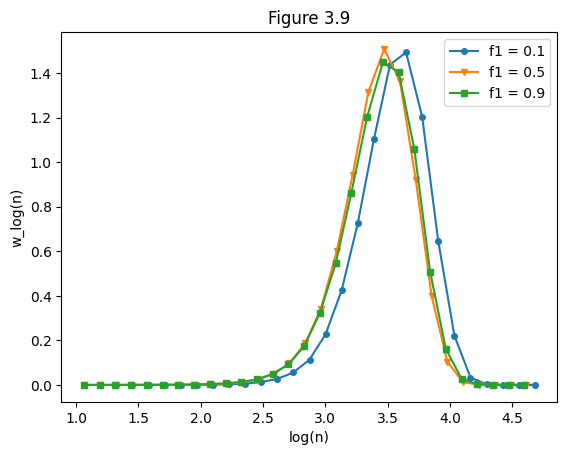

In [24]:
#@title Plot Figure 3.9
for f1, style in zip(feeds, ["o-", "v-", "s-"]):
    D = sims[f1][0]; edges = np.logspace(1, np.log10(3*D.max()), 30)
    mass, _ = np.histogram(D, bins=edges, weights=D); x = np.log10(np.sqrt(edges[1:]*edges[:-1]))
    y = mass / np.diff(np.log10(edges)); y /= np.trapezoid(y, x)
    plt.plot(x, y, style, ms=4, label=f"f1 = {f1}")
plt.xlabel("log(n)"); plt.ylabel("w_log(n)"); plt.legend(); plt.title("Figure 3.9"); plt.show()

## 6 · Figure 3.14: CCD vs. the Stockmayer distribution
**Monte Carlo CCD** (Algorithm 3.4): `F1 = N1/D` per chain, then a histogram over `F1` weighted by chain length (as in Notebook 3).

**Stockmayer CCD** (Eq. 3.64), with `y = F1 − F̄1` and the composition parameter of Eq. 3.61:

In [25]:
def stockmayer_ccd(y, F1bar, beta, tau):
    phi = F1bar * (1 - F1bar) * np.sqrt(1 - 4 * F1bar * (1 - F1bar) * (1 - r1 * r2))
    s = beta + tau
    top = 3 * phi**2 * s * (2 * s * (tau + 1.25 * beta) * phi + y**2 * tau)
    return top / (2 * s * phi + y**2)**3.5

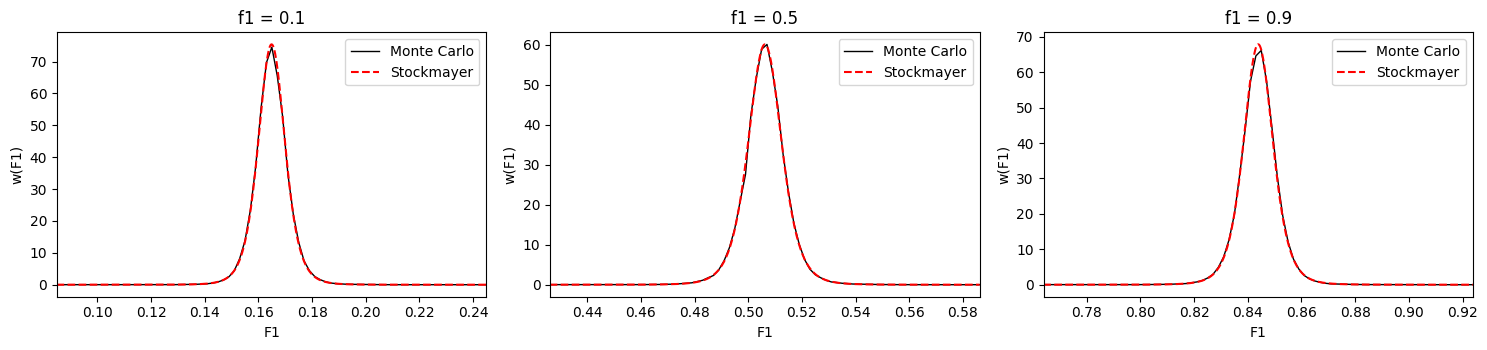

In [26]:
#@title Plot Figure 3.14
fig, ax = plt.subplots(1, 3, figsize=(15, 3.6))
for a, f1 in zip(ax, feeds):
    D, N1 = sims[f1]; F1 = N1 / D; dF = 0.002; edges = np.arange(0, 1 + dF, dF)
    Y, _ = np.histogram(F1, bins=edges, weights=D); F1bar = N1.sum() / D.sum()
    P, Q, Rp, RtM, Rtc = overall_rates(f1); Fg = np.linspace(0, 1, 4001)
    a.plot(0.5*(edges[1:] + edges[:-1]), Y / Y.sum() / dF, "k-", lw=1, label="Monte Carlo")
    a.plot(Fg, stockmayer_ccd(Fg - F1bar, F1bar, Rtc/Rp, RtM/Rp), "r--", label="Stockmayer")
    a.set_xlim(F1bar - 0.08, F1bar + 0.08); a.set_xlabel("F1"); a.set_ylabel("w(F1)"); a.set_title(f"f1 = {f1}"); a.legend()
plt.tight_layout(); plt.show()

## 7 · Figure 3.16: bivariate CLD × CCD
Monte Carlo (Algorithm 3.5, a 2D histogram weighted by chain length) next to the Stockmayer bivariate distribution (Eq. 3.58), on a log(n) axis (Eq. 3.69), for `f1 = 0.5`. Chains shorter than 100 units are left out: with so few units, they can only have a handful of different compositions.

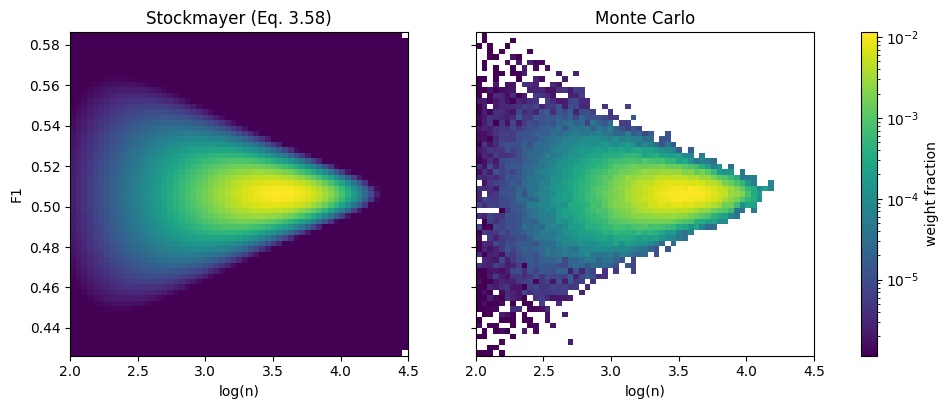

In [27]:
#@title Plot Figure 3.16
D, N1 = sims[0.5]; F1 = N1 / D; F1bar = N1.sum() / D.sum()
P, Q, Rp, RtM, Rtc = overall_rates(0.5); b, t = Rtc/Rp, RtM/Rp; s = b + t
phi = F1bar*(1 - F1bar)*np.sqrt(1 - 4*F1bar*(1 - F1bar)*(1 - r1*r2))
logn_edges = np.linspace(2, 4.5, 60); F_edges = np.linspace(F1bar - 0.08, F1bar + 0.08, 60)
M_mc, _, _ = np.histogram2d(np.log10(D), F1, bins=[logn_edges, F_edges], weights=D); M_mc /= M_mc.sum()
lg = 0.5*(logn_edges[1:] + logn_edges[:-1]); Fc = 0.5*(F_edges[1:] + F_edges[:-1])
nn, FF = np.meshgrid(10**lg, Fc, indexing="ij"); y = FF - F1bar
w_ny = nn*s*(t + 0.5*b*s*nn)*np.exp(-s*nn) * np.sqrt(nn/(2*np.pi*phi)) * np.exp(-nn*y**2/(2*phi))
M_st = 2.3026*nn*w_ny; M_st /= M_st.sum()
fig, ax = plt.subplots(1, 2, figsize=(12, 4.2), sharey=True); vmax = max(M_mc.max(), M_st.max())
for a, Mx, title in [(ax[0], M_st, "Stockmayer (Eq. 3.58)"), (ax[1], M_mc, "Monte Carlo")]:
    pc = a.pcolormesh(logn_edges, F_edges, Mx.T, cmap="viridis", norm=LogNorm(vmin=vmax*1e-4, vmax=vmax))
    a.set_xlabel("log(n)"); a.set_title(title)
ax[0].set_ylabel("F1"); fig.colorbar(pc, ax=ax, label="weight fraction"); plt.show()

## ✅ What the code taught us
- 18 probabilities, one idea: a **hierarchy** of `Rnd ≤ P` decisions (propagate? → which monomer? / combine? → which monomer receives the transfer?).
- Indexing probabilities by the terminal unit (`Pp[last]`) keeps the Terminal model compact.
- Three independent checks (Stockmayer averages, Mayo–Lewis, Stockmayer CCD) all agree with the simulation.

### 🧪 Try it yourself
1. Run `f1 = 0.3` and `0.7`. Where is the minimum in Nn?
2. Set `r1 = r2 = 1` (Bernoullian) and re-run from section 1. How does the CCD width change?
3. Make the CCD bins 10× finer (`dF = 0.0002`). When does the Monte Carlo CCD become too noisy, and how many chains fix it?

➡️ **Next: Notebook 10 — Dynamic Monte Carlo case study: choosing the control volume**